<!-- Dr. Nam H. Le. drnamlabs.com, bunnyquant.com -->
# 01. The simplest cases: how much outside information keeps a self-rewriting memory alive?

**Question** (see `QUESTION.md`): a memory that overwrites its stored patterns with its own retrievals
loses its landscape. How much outside information per step does it need to stay adapted?
"Adapted" means **K\***, the number of basins in the landscape.

**Story.** A library copies books by asking itself what a book *probably* says and filing the answer.
Each copy is slightly blurred toward what the library already holds. With nothing new coming in,
the shelves converge. Now let a fraction α of new books come from outside. How large must α be?

We build the answer from the smallest system up:

1. **Case 0.** Two memories ±m: when are there two basins? (a pitchfork)
2. **Case 1.** Let the memory rewrite itself (α = 0): a cobweb into collapse.
3. **Case 2.** Add outside information α: a fold, bistability and hysteresis.
4. **Case 3.** A real stochastic bank of K points in 2-D: does the simulation follow the map?

In [1]:
# Dr. Nam H. Le. drnamlabs.com, bunnyquant.com
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from pathlib import Path
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## Case 0. Two memories, one query: when are there two basins?

Store two patterns, +m and −m, on a line. A query x is retrieved by attention with sharpness β:
it scores both memories, β·(+m)·x and β·(−m)·x, takes the softmax, and returns the weighted average.
For two memories that average is exactly

  **f(x) = m · tanh(β m x)**

Iterating f is the retrieval dynamics. Its fixed points are the basins' bottoms.

*Example.* With m = 1 and β = 0.5, f(x) = tanh(0.5x) lies below the diagonal everywhere,
so every query slides to 0, the mean. There is one basin and the memory cannot tell +1 from −1.
With β = 2, f crosses the diagonal at ±0.96. There are two basins and the memory works.

The switch happens where the slope of f at 0, which is **β m²**, passes 1. This is a pitchfork bifurcation,
the same picture as the logistic map's first split.

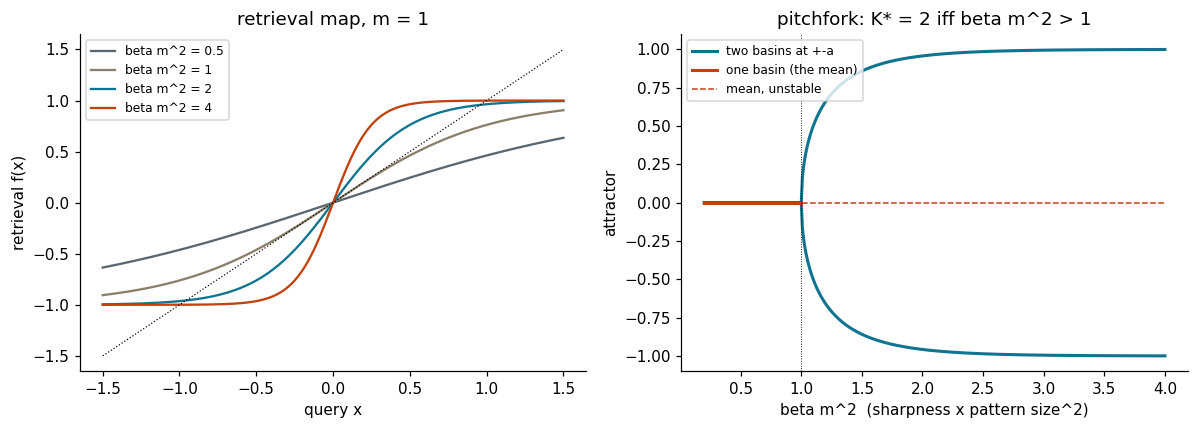

In [2]:
def a_of(m, beta):
    """Positive fixed point of x = m tanh(beta m x); 0 if beta m^2 <= 1."""
    if beta * m * m <= 1:
        return 0.0
    return brentq(lambda x: x - m * np.tanh(beta * m * x), 1e-12, m)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = np.linspace(-1.5, 1.5, 300)
for b, c in zip([0.5, 1.0, 2.0, 4.0], ['#5a6670', '#8a7f6a', '#0e7490', '#c2410c']):
    ax[0].plot(x, np.tanh(b * x), color=c, label=f'beta m^2 = {b:g}')
ax[0].plot(x, x, 'k:', lw=0.8)
ax[0].set(xlabel='query x', ylabel='retrieval f(x)', title='retrieval map, m = 1')
ax[0].legend(fontsize=8)
g = np.linspace(0.2, 4, 400)
up = np.array([a_of(1.0, b) for b in g])
ax[1].plot(g, up, color='#0e7490', lw=2, label='two basins at +-a')
ax[1].plot(g, -up, color='#0e7490', lw=2)
ax[1].plot(g[g <= 1], 0 * g[g <= 1], color='#c2410c', lw=2, label='one basin (the mean)')
ax[1].plot(g[g > 1], 0 * g[g > 1], '--', color='#c2410c', lw=1, label='mean, unstable')
ax[1].axvline(1, color='k', lw=0.6, ls=':')
ax[1].set(xlabel='beta m^2  (sharpness x pattern size^2)', ylabel='attractor', title='pitchfork: K* = 2 iff beta m^2 > 1')
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'case0_pitchfork.png'); plt.show()

**Reading.** The attractor a(m) is always *smaller* than the stored pattern m (it lies below m on the left plot's diagonal).
Retrieval blurs toward the mean, and that is the seed of collapse.

## Case 1. The memory rewrites itself (α = 0)

Each step replaces a fraction η of the stored pattern with what the memory retrieves:

  **m ← (1 − η) m + η a(m)**

Because a(m) < m, m can only shrink. When it crosses **m_c = 1/√β**, the pitchfork closes:
a = 0, K* drops from 2 to 1, and from then on the memory writes the mean.

*Example.* β = 2, m₀ = 1, η = 0.05. The cobweb staircase below walks m down to 1/√2 ≈ 0.71.
There the landscape dies, *before* the patterns themselves have gone. In the paper this was "the landscape dies first".

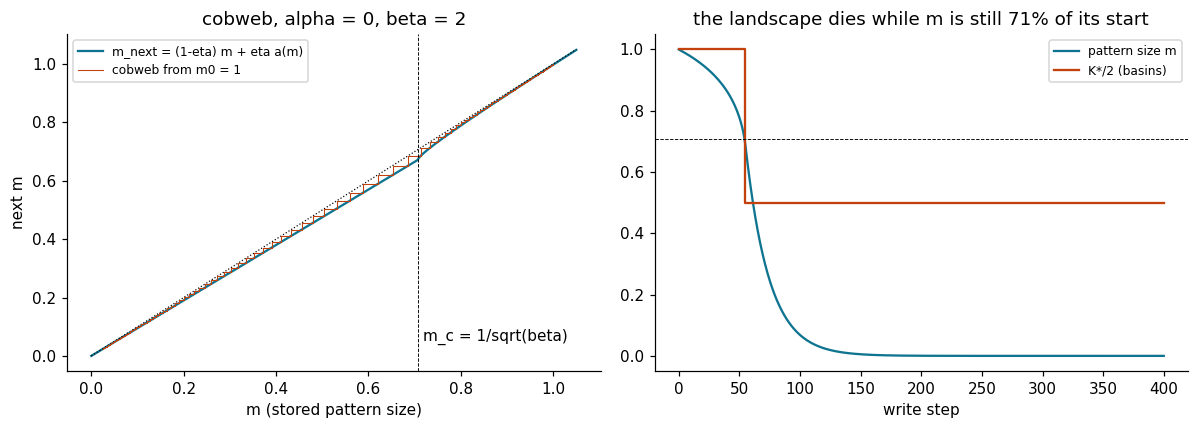

basins die at step 55  m there = 0.687


In [3]:
beta, eta = 2.0, 0.05
mc = 1 / np.sqrt(beta)
step = lambda m, al=0.0, m0=1.0: (1 - eta) * m + eta * ((1 - al) * a_of(m, beta) + al * m0)
traj = [1.0]
for _ in range(400):
    traj.append(step(traj[-1]))
traj = np.array(traj)
Kt = np.where(beta * traj**2 > 1, 2, 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
mm = np.linspace(0, 1.05, 300)
ax[0].plot(mm, [step(v) for v in mm], color='#0e7490', label='m_next = (1-eta) m + eta a(m)')
ax[0].plot(mm, mm, 'k:', lw=0.8)
cx, cy = [traj[0]], [traj[0]]
for i in range(0, 120):
    cx += [traj[i], traj[i + 1]]; cy += [traj[i + 1], traj[i + 1]]
ax[0].plot(cx, cy, color='#c2410c', lw=0.7, label='cobweb from m0 = 1')
ax[0].axvline(mc, color='k', lw=0.6, ls='--'); ax[0].text(mc + 0.01, 0.05, 'm_c = 1/sqrt(beta)')
ax[0].set(xlabel='m (stored pattern size)', ylabel='next m', title='cobweb, alpha = 0, beta = 2'); ax[0].legend(fontsize=8)
ax[1].plot(traj, color='#0e7490', label='pattern size m')
ax[1].plot(Kt / 2, color='#c2410c', drawstyle='steps-post', label='K*/2 (basins)')
ax[1].axhline(mc, color='k', lw=0.6, ls='--')
ax[1].set(xlabel='write step', title='the landscape dies while m is still 71% of its start'); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'case1_cobweb.png'); plt.show()
print('basins die at step', int(np.argmax(Kt == 1)), ' m there =', round(traj[np.argmax(Kt == 1)], 3))

## Case 2. Add outside information α

Now a fraction α of each write is a fresh outside sample of size m₀ = 1:

  **m ← (1 − η) m + η [ (1 − α) a(m) + α m₀ ]**

The stationary states satisfy m = (1 − α) a(m) + α m₀. Solve for α instead:

  **α(m) = (m − a(m)) / (m₀ − a(m))**

and plot m* against α. Below m_c we have a = 0, so the dead state is m* = α m₀. It exists only while α m₀ < m_c,
which gives **α_c = 1/(m₀ √β)**.

*What we expected:* a smooth curve. *What the map gives:* the alive branch folds back.
For α between α_min and α_c, an alive and a dead state coexist. That is a **saddle-node with hysteresis**:
a memory that has already collapsed needs α > α_c to come back, while one that is alive survives down to α_min.

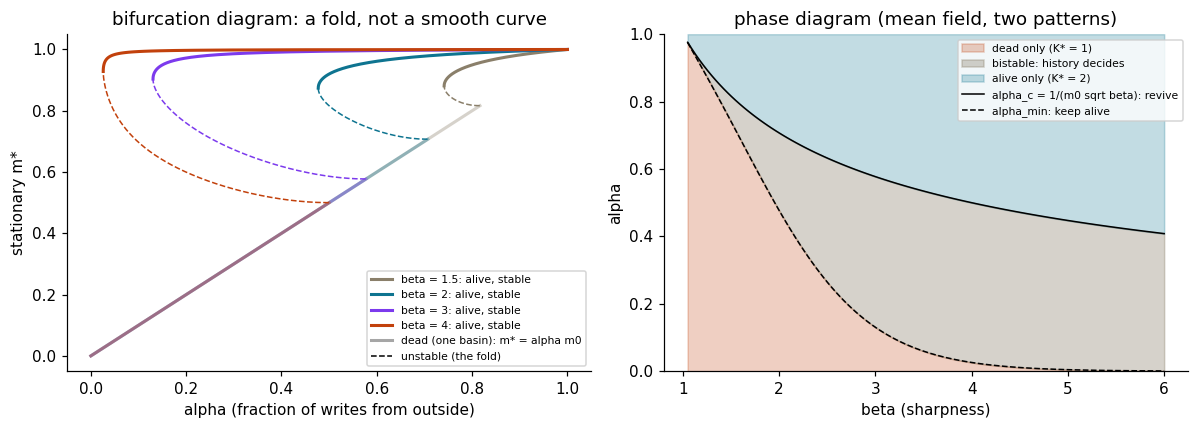

beta=1.5: alpha_min=0.741  alpha_c=0.816
beta=2: alpha_min=0.477  alpha_c=0.707
beta=3: alpha_min=0.130  alpha_c=0.577
beta=4: alpha_min=0.026  alpha_c=0.500


In [4]:
def branches(beta, m0=1.0, n=600):
    mc = 1 / np.sqrt(beta)
    ms = np.linspace(mc * (1 + 1e-6), m0 * (1 - 1e-9), n)
    al = []
    for m in ms:
        a = a_of(m, beta)
        al.append((m - a) / (m0 - a) if m0 - a > 1e-12 else np.nan)
    return ms, np.array(al)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for b, c in zip([1.5, 2.0, 3.0, 4.0], ['#8a7f6a', '#0e7490', '#7c3aed', '#c2410c']):
    ms, al = branches(b)
    i = np.nanargmin(al)
    ax[0].plot(al[i:], ms[i:], color=c, lw=2, label=f'beta = {b:g}: alive, stable')
    ax[0].plot(al[:i + 1], ms[:i + 1], color=c, lw=1, ls='--')
    ac = 1 / np.sqrt(b)
    aa = np.linspace(0, ac, 50)
    ax[0].plot(aa, aa, color=c, lw=2, alpha=0.35)
ax[0].plot([], [], 'k', lw=2, alpha=0.35, label='dead (one basin): m* = alpha m0')
ax[0].plot([], [], 'k--', lw=1, label='unstable (the fold)')
ax[0].set(xlabel='alpha (fraction of writes from outside)', ylabel='stationary m*', title='bifurcation diagram: a fold, not a smooth curve')
ax[0].legend(fontsize=7)

bs = np.linspace(1.05, 6, 120)
amin = np.array([np.nanmin(branches(b, n=300)[1]) for b in bs])
ac = 1 / np.sqrt(bs)
ax[1].fill_between(bs, 0, np.minimum(amin, ac), color='#c2410c', alpha=0.25, label='dead only (K* = 1)')
ax[1].fill_between(bs, amin, ac, color='#8a7f6a', alpha=0.35, label='bistable: history decides')
ax[1].fill_between(bs, ac, 1, color='#0e7490', alpha=0.25, label='alive only (K* = 2)')
ax[1].plot(bs, ac, color='k', lw=1, label='alpha_c = 1/(m0 sqrt beta): revive')
ax[1].plot(bs, amin, color='k', lw=1, ls='--', label='alpha_min: keep alive')
ax[1].set(xlabel='beta (sharpness)', ylabel='alpha', ylim=(0, 1), title='phase diagram (mean field, two patterns)')
ax[1].legend(fontsize=7, loc='upper right')
fig.tight_layout(); fig.savefig(FIG / 'case2_fold_phase.png'); plt.show()
for b in [1.5, 2, 3, 4]:
    print(f'beta={b}: alpha_min={np.nanmin(branches(b)[1]):.3f}  alpha_c={1/np.sqrt(b):.3f}')

## Case 3. A real bank: K points in 2-D, the paper's update rule

Now drop the mean-field assumptions. The environment is two noisy clusters at (±1, 0) with spread 0.1.
The bank holds K = 20 points. Each step:

- pick a random slot;
- with probability α, write a fresh environment sample there;
- otherwise draw an environment query, relax it with attention (dot-product, sharpness β) to a fixed point, and write that.

K\* is counted by a census: relax 30 probes and count the distinct fixed points.
We sweep α **up** from a dead bank and **down** from an alive bank. If the fold is real, the two sweeps should disagree.

In [5]:
def relax(x, X, beta, it=300):
    for _ in range(it):
        z = beta * X @ x; z -= z.max(); w = np.exp(z); w /= w.sum()
        xn = w @ X
        if np.abs(xn - x).max() < 1e-10:
            return xn
        x = xn
    return x

def env(rng, n, s=0.1):
    sg = rng.choice([-1, 1], n)
    return np.c_[sg * 1.0, np.zeros(n)] + s * rng.standard_normal((n, 2))

PROBES = env(np.random.default_rng(9), 30, s=0.3)

def census(X, beta):
    reps = []
    for p in PROBES:
        x = relax(p, X, beta)
        if not any(np.linalg.norm(x - r) < 1e-3 for r in reps):
            reps.append(x)
    return len(reps)

def run_bank(beta, alpha, X0, T, seed, snap_every=0):
    rng = np.random.default_rng(seed); X = X0.copy(); K = len(X); snaps = []
    for t in range(T):
        if snap_every and t % snap_every == 0:
            snaps.append(X.copy())
        j = rng.integers(K); q = env(rng, 1)[0]
        X[j] = q if rng.random() < alpha else relax(q, X, beta)
    return X, snaps

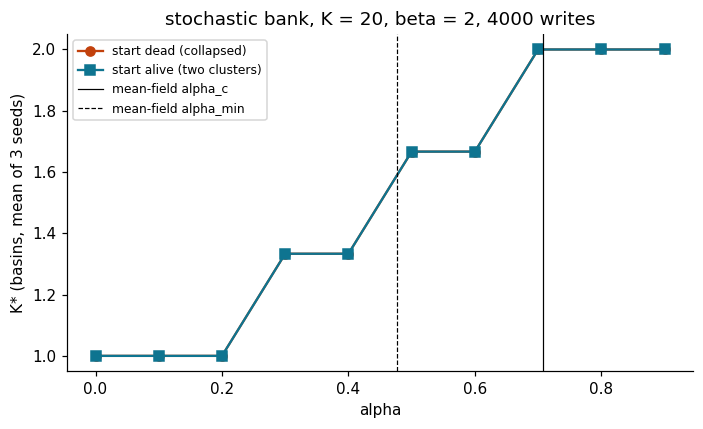

up   [1.         1.         1.         1.33333333 1.33333333 1.66666667
 1.66666667 2.         2.         2.        ]
down [1.         1.         1.         1.33333333 1.33333333 1.66666667
 1.66666667 2.         2.         2.        ]


In [6]:
K, T, beta = 20, 4000, 2.0
alphas = np.round(np.arange(0.0, 0.95, 0.1), 2)
seeds = range(3)
up, down = np.zeros((len(seeds), len(alphas))), np.zeros((len(seeds), len(alphas)))
for si, s in enumerate(seeds):
    rng = np.random.default_rng(100 + s)
    dead0 = np.zeros((K, 2)) + 0.01 * rng.standard_normal((K, 2))   # collapsed bank at the mean
    alive0 = env(rng, K)                                              # fresh bank, two clusters
    for ai, al in enumerate(alphas):
        up[si, ai] = census(run_bank(beta, al, dead0, T, s)[0], beta)
        down[si, ai] = census(run_bank(beta, al, alive0, T, s)[0], beta)

ms, al_curve = branches(beta)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(alphas, up.mean(0), 'o-', color='#c2410c', label='start dead (collapsed)')
ax.plot(alphas, down.mean(0), 's-', color='#0e7490', label='start alive (two clusters)')
ax.axvline(1 / np.sqrt(beta), color='k', ls='-', lw=0.8, label='mean-field alpha_c')
ax.axvline(np.nanmin(al_curve), color='k', ls='--', lw=0.8, label='mean-field alpha_min')
ax.set(xlabel='alpha', ylabel='K* (basins, mean of 3 seeds)', title=f'stochastic bank, K = {K}, beta = {beta:g}, {T} writes')
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / 'case3_hysteresis.png'); plt.show()
print('up  ', up.mean(0)); print('down', down.mean(0))

## Case 3, seen: the bank, its energy and its retrieval field

Left: α = 0. Right: α = 0.6. Contours show the energy E(x) = −(1/β) log Σ exp(β ξ·x) + ½|x|².
Arrows show where one retrieval step moves a query (f(x) − x). Dots are the stored patterns.
The animation is saved to `figures/case3_bank.gif`.

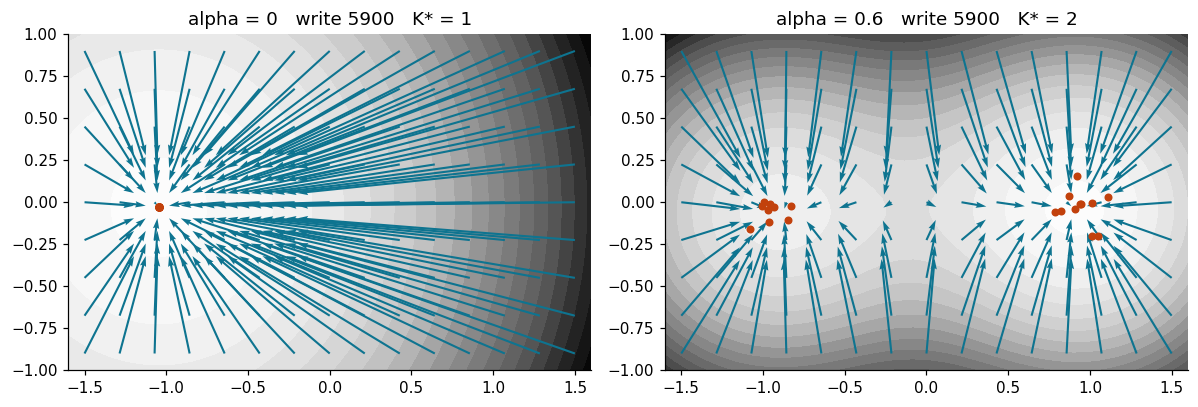

In [7]:
from matplotlib.animation import FuncAnimation, PillowWriter
beta_g, T_g, every = 2.0, 6000, 100
X0 = env(np.random.default_rng(5), 20)
runs = {a: run_bank(beta_g, a, X0, T_g, 5, snap_every=every)[1] for a in (0.0, 0.6)}
gx, gy = np.meshgrid(np.linspace(-1.6, 1.6, 60), np.linspace(-1.0, 1.0, 40))
G = np.c_[gx.ravel(), gy.ravel()]
qx, qy = np.meshgrid(np.linspace(-1.5, 1.5, 15), np.linspace(-0.9, 0.9, 9))
Q = np.c_[qx.ravel(), qy.ravel()]

def energy(X):
    z = beta_g * G @ X.T; zm = z.max(1, keepdims=True)
    return (-(zm[:, 0] + np.log(np.exp(z - zm).sum(1))) / beta_g + 0.5 * (G**2).sum(1)).reshape(gx.shape)

def field(X):
    z = beta_g * Q @ X.T; z -= z.max(1, keepdims=True); w = np.exp(z); w /= w.sum(1, keepdims=True)
    return w @ X - Q

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
def draw(k):
    for ax, a in zip(axs, (0.0, 0.6)):
        ax.clear(); X = runs[a][k]
        ax.contourf(gx, gy, energy(X), levels=20, cmap='Greys')
        F = field(X); ax.quiver(Q[:, 0], Q[:, 1], F[:, 0], F[:, 1], color='#0e7490', angles='xy', scale_units='xy', scale=1.5, width=0.004)
        ax.scatter(X[:, 0], X[:, 1], s=18, color='#c2410c', zorder=3)
        ax.set(xlim=(-1.6, 1.6), ylim=(-1.0, 1.0), title=f'alpha = {a:g}   write {k * every}   K* = {census(X, beta_g)}')
    fig.tight_layout()
anim = FuncAnimation(fig, draw, frames=len(runs[0.0]), interval=120)
anim.save(FIG / 'case3_bank.gif', writer=PillowWriter(fps=8))
draw(len(runs[0.0]) - 1); fig.savefig(FIG / 'case3_bank_final.png'); plt.show()

## What the simplest cases say

1. **Pitchfork (case 0).** Two memories have two basins iff beta m^2 > 1. Retrieval always returns something smaller than what is stored.
2. **Collapse at alpha = 0 (case 1).** In the map, the landscape dies at step 55 while m is still 0.69 of its start: the landscape dies before the patterns do.
3. **Mean field predicts a fold (case 2).** It gives bistability between alpha_min and alpha_c = 1/(m0 sqrt beta). At beta = 2 that is 0.48 to 0.71.
4. **The real bank does NOT show the fold (case 3).** Sweeping up from a dead bank and down from an alive bank gives identical K* at every alpha, so there is no hysteresis. The bank forgets its start within 4000 writes. The mean-field fold assumes all slots share one size m, but a real bank keeps fresh points at full size, and a handful of them is enough to reopen a basin.
5. **The real collapse is fixation, not shrinkage.** At alpha = 0 every slot ends on ONE cluster (left panel, a point at (-1, 0)), not at the mean.
6. **The crossover sits between the two mean-field lines.** K* rises from 1 to 2 over alpha ~ 0.3 to 0.7 at beta = 2, K = 20 (3 seeds). Whether it is sharp is the next test: if the rise steepens as K grows (20, 40, 80), there is a true transition.

Next: (a) K-scaling of the alpha sweep at beta = 2 and 4, 10 seeds; (b) a mean-field model with TWO populations (fresh vs self-written points) instead of one size m.